In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip install nibabel matplotlib

import os
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np


cale_folder = '/content/drive/MyDrive/PI-proiect/MRA_IXI_HH'
folder_imagini = os.path.join(cale_folder, "imagesTr")
folder_masti = os.path.join(cale_folder, "cow_seg_labelsTr")



In [6]:
import time
import cv2

def gaseste_masca(nume_imagine):
    # Numele imaginii e ceva de genul "IXI012-HH-1211-MRA_LPS_DFmasked_ROI-braincase.nii.gz"
    # Vrem să extragem doar "IXI012-HH-1211"
    id_pacient = nume_imagine.split('-MRA')[0]

    # Căutăm în folderul de măști un fișier care începe cu acel ID
    for fisier in os.listdir(folder_masti):
        if fisier.startswith(id_pacient):
            return fisier
    return None


toate_imaginile = []
toate_mastile = []


fisiere_imagini = os.listdir(folder_imagini)

print(f"Începem procesarea a {len(fisiere_imagini)} pacienți...")
start_time = time.time()

# Mărimea standard pe care o cer rețelele neuronale (256x256)
IMG_SIZE = 256


for nume_img in fisiere_imagini:
    nume_msk = gaseste_masca(nume_img)
    if nume_msk is None:
          continue

    cale_imagine = os.path.join(folder_imagini, nume_img)
    cale_masca = os.path.join(folder_masti, nume_msk)

    volum_3d = nib.load(cale_imagine).get_fdata()
    volum_masca = nib.load(cale_masca).get_fdata()

     # Normalizare
    volum_3d = (volum_3d - np.mean(volum_3d)) / (np.std(volum_3d) + 1e-8)

    for i in range(volum_3d.shape[2]):
          masca_felie = volum_masca[:, :, i]

          if np.sum(masca_felie > 0) > 10:

            felie_img = volum_3d[:, :, i]
            felie_msk = (masca_felie > 0).astype(np.float32)

             # Redimensionare
            felie_img = cv2.resize(felie_img, (IMG_SIZE, IMG_SIZE))
            felie_msk = cv2.resize(felie_msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

            toate_imaginile.append(felie_img)
            toate_mastile.append(felie_msk)

             # 4. Creăm o imagine oglindită
            img_flip = np.fliplr(felie_img).copy()
            msk_flip = np.fliplr(felie_msk).copy()

            toate_imaginile.append(img_flip)
            toate_mastile.append(msk_flip)

print(f"Am strâns {len(toate_imaginile)} felii 2D în total.")
print(f"A durat {time.time() - start_time:.2f} secunde.")

Începem procesarea a 20 pacienți...
Am strâns 1818 felii 2D în total.
A durat 55.21 secunde.


In [7]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# 1. Împărțim datele: 80% pentru antrenare, 20% pentru validare
X_train, X_val, y_train, y_val = train_test_split(
    toate_imaginile, toate_mastile, test_size=0.2, random_state=42
)

# 2. Creăm clasa custom pentru Dataset
class VesselDataset(Dataset):
    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # Luăm imaginea și masca
        img = self.images[idx]
        mask = self.masks[idx]

        # Transformăm în tensori (1 canal, Înălțime, Lățime)
        img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0)
        mask_tensor = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return img_tensor, mask_tensor

# 3. Creăm seturile de date
train_dataset = VesselDataset(X_train, y_train)
val_dataset = VesselDataset(X_val, y_val)

# 4. Le împachetează câte 8 pentru a nu bloca memoria
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

print(f"Datele sunt pregătite pentru U-Net")
print(f"Train: {len(train_dataset)} felii")
print(f"Validare: {len(val_dataset)} felii")

Datele sunt pregătite pentru U-Net
Train: 1454 felii
Validare: 364 felii


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
    )
  def forward(self, input_image):
      return self.conv(input_image)

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

         # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.out = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder cu Skip Connections
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        # output
        return self.out(d1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet().to(device)

print(f"Modelul U-Net a fost creat cu succes")
print(f" Rulează pe: {device}")

Modelul U-Net a fost creat cu succes
 Rulează pe: cuda


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, predictii, masti, smooth=1e-6):
        # Calculăm BCE standard
        bce_loss = self.bce(predictii, masti)

        # Trecem predicțiile prin sigmoid pentru a avea probabilități între 0 și 1
        predictii = torch.sigmoid(predictii)

        # Calculăm Dice Loss
        # Aplatizăm tensorii pentru a calcula suprapunerea
        predictii_flat = predictii.view(-1)
        masti_flat = masti.view(-1)

        intersectie = (predictii_flat * masti_flat).sum()
        dice_score = (2.0 * intersectie + smooth) / (predictii_flat.sum() + masti_flat.sum() + smooth)
        dice_loss = 1.0 - dice_score

        # Returnăm media combinată
        return bce_loss + dice_loss


criterion = DiceBCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [10]:
import time

# Vom antrena modelul timp de 5 epoci
NUM_EPOCHS = 5

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0

    for batch_idx, (imagini, masti) in enumerate(train_loader):
       # Mutăm datele pe GPU
        imagini = imagini.to(device)
        masti = masti.to(device)

        # Curățăm gradienții vechi
        optimizer.zero_grad()

        # Trecem imaginile prin rețeaua U-Net
        predictii = model(imagini)

         # Calculăm eroarea (Loss)
        loss = criterion(predictii, masti)

        # Calculăm gradienții
        loss.backward()

        # Optimizatorul face corecția efectivă
        optimizer.step()

        # Adunăm eroarea pentru a face media la finalul epocii
        train_loss += loss.item()

        # Afișăm progresul la fiecare 10 pachete
        if batch_idx % 10 == 0:
            print(f"Epoca {epoch+1}/{NUM_EPOCHS} | Pachetul {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}")

    # La finalul epocii, calculăm media erorii
    avg_train_loss = train_loss / len(train_loader)

    # Validare
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for imagini, masti in val_loader:
            imagini = imagini.to(device)
            masti = masti.to(device)

            predictii = model(imagini)
            loss = criterion(predictii, masti)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    print(f" Epoca {epoch+1}: Train Loss = {avg_train_loss:.4f} | Val Loss = {avg_val_loss:.4f}")
    print("-" * 50)

print(f" Antrenare completă. A durat {time.time() - start_time:.2f} secunde.")

Epoca 1/5 | Pachetul 0/182 | Loss: 1.8420
Epoca 1/5 | Pachetul 10/182 | Loss: 1.3869
Epoca 1/5 | Pachetul 20/182 | Loss: 1.3076
Epoca 1/5 | Pachetul 30/182 | Loss: 1.2321
Epoca 1/5 | Pachetul 40/182 | Loss: 1.1900
Epoca 1/5 | Pachetul 50/182 | Loss: 1.1623
Epoca 1/5 | Pachetul 60/182 | Loss: 1.1245
Epoca 1/5 | Pachetul 70/182 | Loss: 1.0785
Epoca 1/5 | Pachetul 80/182 | Loss: 1.0674
Epoca 1/5 | Pachetul 90/182 | Loss: 1.0566
Epoca 1/5 | Pachetul 100/182 | Loss: 1.0054
Epoca 1/5 | Pachetul 110/182 | Loss: 1.0236
Epoca 1/5 | Pachetul 120/182 | Loss: 0.9959
Epoca 1/5 | Pachetul 130/182 | Loss: 0.9560
Epoca 1/5 | Pachetul 140/182 | Loss: 0.9565
Epoca 1/5 | Pachetul 150/182 | Loss: 0.9151
Epoca 1/5 | Pachetul 160/182 | Loss: 0.8725
Epoca 1/5 | Pachetul 170/182 | Loss: 0.8533
Epoca 1/5 | Pachetul 180/182 | Loss: 0.7476
 Epoca 1: Train Loss = 1.0698 | Val Loss = 0.7380
--------------------------------------------------
Epoca 2/5 | Pachetul 0/182 | Loss: 0.7102
Epoca 2/5 | Pachetul 10/182 | Lo

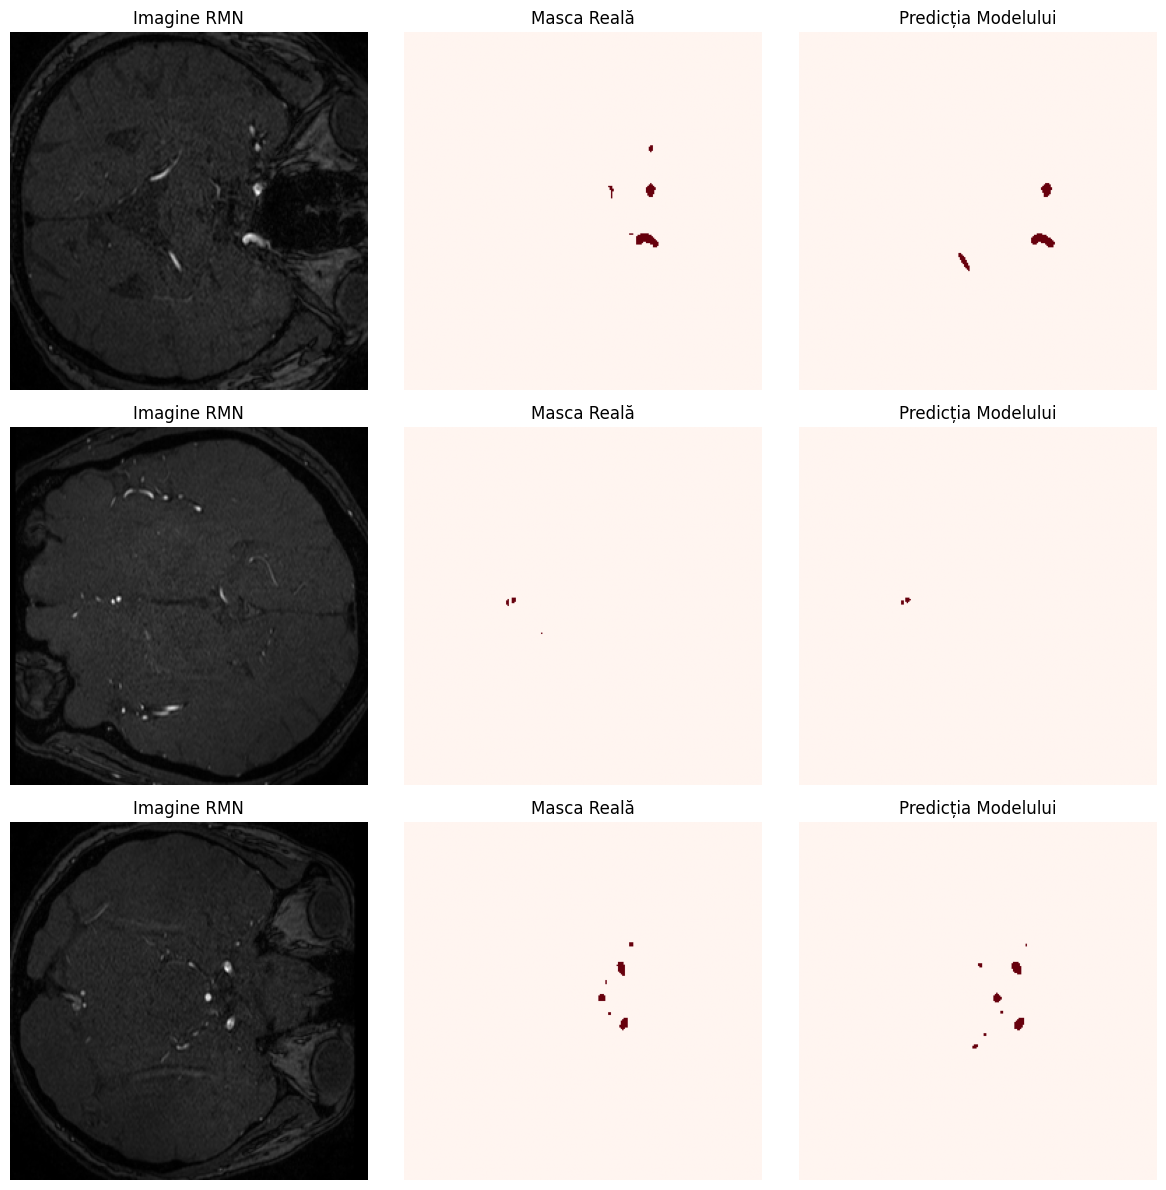

In [11]:
import matplotlib.pyplot as plt
import torch

def vizualizeaza_rezultate(model, loader, device):
    model.eval()

    # Luăm un singur batch de imagini din setul de validare
    imagini, masti_reale = next(iter(loader))

    # Le mutăm pe GPU
    imagini = imagini.to(device)

    with torch.no_grad():
        predictii_logits = model(imagini)
        # Transformăm logits în probabilități (0-1) folosind Sigmoid
        predictii = torch.sigmoid(predictii_logits)

        imagini = imagini.cpu().numpy()
        masti_reale = masti_reale.cpu().numpy()
        predictii = predictii.cpu().numpy()

        fig, axes = plt.subplots(3, 3, figsize=(12, 12))

        for i in range(3):
          # Imaginea RMN
          axes[i, 0].imshow(imagini[i, 0, :, :], cmap='gray')
          axes[i, 0].set_title("Imagine RMN")
          axes[i, 0].axis('off')

          # Masca Reală
          axes[i, 1].imshow(masti_reale[i, 0, :, :], cmap='Reds')
          axes[i, 1].set_title("Masca Reală")
          axes[i, 1].axis('off')

          # Predicția Rețelei
          masca_prezisa = predictii[i, 0, :, :] > 0.5
          axes[i, 2].imshow(masca_prezisa, cmap='Reds')
          axes[i, 2].set_title("Predicția Modelului")
          axes[i, 2].axis('off')


    plt.tight_layout()
    plt.savefig('rezultate.png')
    plt.show()

vizualizeaza_rezultate(model, val_loader, device)

In [12]:
import torch

def dice_score(model, loader, device):
  model.eval()

  total_dice= 0.0
  nr_pachete=0

  with torch.no_grad():
    for imagini, masti_reale in loader:
      imagini = imagini.to(device)
      masti_reale = masti_reale.to(device)

      predictii_logits = model(imagini)
      predictii_logits = torch.sigmoid(predictii_logits)

      predictii_binar = (predictii_logits > 0.5).float()

      intersectie = (predictii_binar * masti_reale).sum()
      suma_totala = predictii_binar.sum() + masti_reale.sum()

      dice = (2.0 * intersectie + 1e-6) / (suma_totala + 1e-6)

      total_dice += dice.item()
      nr_pachete += 1

  scor_final = total_dice / nr_pachete
  return scor_final

scor = dice_score(model, val_loader, device)
print(f" Scorul Dice pe setul de validare: {scor:.4f}")

 Scorul Dice pe setul de validare: 0.7997


In [13]:
import torch

# Salvăm doar "greutățile" (weights) modelului
nume_fisier = 'model_brain_vessels.pth'
torch.save(model.state_dict(), nume_fisier)

print(f"✅ Modelul a fost salvat ca '{nume_fisier}'!")

✅ Modelul a fost salvat ca 'model_brain_vessels.pth'!


In [15]:
import numpy as np
import torch
import nibabel as nib
import os
import cv2

def reconstructie_3d(nume_img, model, device, output_folder):
    nume_msk = gaseste_masca(nume_img)
    if nume_msk is None:
        print(f"Nu s-a găsit mască pentru {nume_img}")
        return

    cale_img = os.path.join(folder_imagini, nume_img)
    cale_msk = os.path.join(folder_masti, nume_msk)

    img_nifti = nib.load(cale_img)
    volum_original = img_nifti.get_fdata()

    # Normalizare
    volum_original = (volum_original - np.mean(volum_original)) / (np.std(volum_original) + 1e-8)

    inaltime, latime, adancime = volum_original.shape
    volum_prezis = np.zeros((inaltime, latime, adancime))


    model.eval()
    for i in range(adancime):
        felie_img = volum_original[:, :, i]
        felie_img_redim = cv2.resize(felie_img, (IMG_SIZE, IMG_SIZE))

        tensor_img = torch.tensor(felie_img_redim, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            predictie = model(tensor_img)
            predictie = torch.sigmoid(predictie)
            masca_2d = (predictie > 0.5).float()

        masca_2d = masca_2d.cpu().numpy()[0, 0, :, :]
        masca_redim = cv2.resize(masca_2d, (latime, inaltime), interpolation=cv2.INTER_NEAREST)
        volum_prezis[:, :, i] = masca_redim


    nifti_prezis = nib.Nifti1Image(volum_prezis, img_nifti.affine)

    nume_scurt = nume_img.split('-MRA')[0]
    cale_salvare = os.path.join(output_folder, f"PREDICTIE_3D_{nume_scurt}.nii.gz")


    nib.save(nifti_prezis, cale_salvare)
    print(f" Salvat: {cale_salvare}")


folder_output_nifti = 'predictii_3d_nifti'
os.makedirs(folder_output_nifti, exist_ok=True)


pacienti_de_procesat = fisiere_imagini[:5]

print(f"Începem generarea fișierelor 3D pentru {len(pacienti_de_procesat)} pacienți...")

for pacient in pacienti_de_procesat:
    reconstructie_3d(pacient, model, device, folder_output_nifti)

print("Gata")

Începem generarea fișierelor 3D pentru 5 pacienți...
 Salvat: predictii_3d_nifti/PREDICTIE_3D_IXI631-HH-2651.nii.gz
 Salvat: predictii_3d_nifti/PREDICTIE_3D_IXI052-HH-1343.nii.gz
 Salvat: predictii_3d_nifti/PREDICTIE_3D_IXI034-HH-1260.nii.gz
 Salvat: predictii_3d_nifti/PREDICTIE_3D_IXI039-HH-1261.nii.gz
 Salvat: predictii_3d_nifti/PREDICTIE_3D_IXI646-HH-2653.nii.gz
Gata
